In [34]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [35]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

1. 훈련데이터 , 테스트 데이터 분리
2. 훈련데이터 2차원 배열 변경
3. 데이터 학습
4. 데이터 예측
5. 정확도
6. 그래프

In [36]:
# 훈련, 테스트 데이터 분리
train_data, test_data, train_label, test_label= train_test_split(perch_length, perch_weight)

In [37]:
# 훈련/테스트 데이터는 2차원 데이터가 되어야함
# 훈련/ 테스트 데이터 2차원 배열 변경

train_data=train_data.reshape(-1,1)
test_data=test_data.reshape(-1,1)

In [38]:
# 다항회귀 형태로 변경 - 컬럼을 2개로 증가시킴
train_poly = np.column_stack((train_data**2, train_data))
test_poly = np.column_stack((test_data**2, test_data))

In [39]:
# 데이터 학습
lr=LinearRegression()

# 다항회귀 : 
lr.fit(train_poly,train_label)

# 데이터 예측
predict = lr.predict(test_poly)
print('예측무게:',predict)

예측무게: [134.72347143 382.10104687 810.25868321 146.51158304 701.40005752
  21.11172507 134.72347143 675.40973005  33.77096083  74.27916503
 112.61644297 576.34573598 867.62638555 230.52868387]


In [40]:
# 정확도
score= lr.score(train_poly,train_label)
score2= lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.9672269153710688
test정확도 :  0.9940494585130892


In [41]:
print('기울기:',lr.coef_)
print('y절편:',lr.intercept_)

기울기: [  0.97946316 -20.00988756]
y절편: 100.88082674244305


In [42]:
in_data=input('농어의 길이를 입력하세요')
in_data=float(in_data)

result = lr.predict([[in_data**2,in_data]])
print(result)
print(f'농어 예측 무게: {result[0]:.2f}g')

[382.10104687]
농어 예측 무게: 382.10g


- 데이터가 곡선모양, 선행회귀로는 예측이 어려운 데이터
-> 다항회귀로 하는게 예측 정확도가 높아질 데이터

- 기울기 [0]* 그래프 위치값(길이)**2 + 기울기 [1]*그래프 위치값(길이)+y절편

In [43]:
point=np.arange(10,51)

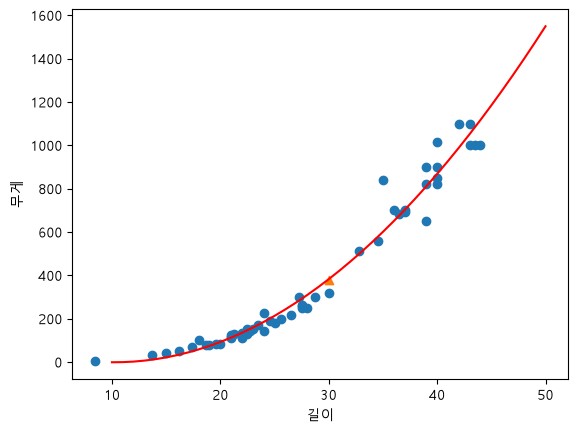

In [45]:
# 산점도 그래프

plt.scatter(perch_length,perch_weight)
plt.scatter(30,376, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_,color='r')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()
